# ES 5201 Homework 4

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 3A

In [2]:
# 3A

# Given parameters
t_s = 0      # Start time
t_e = 20     # End time
f_s = 1      # Start frequency at t = 0
f_e = 4      # End frequency at t = 20

# At t = 0, f(0) = f0
# f(t) = f0 + 2*b*t
# t = 0:
# f(0) = f0 + 2*b*(0) = f0
f0 = f_s
print(f"f0 = {f0} Hz")

# At t = 20; f(20) = f0 + 2*b*(20)
# f(20) = 4 Hz; f0 = 1 Hz
# 4 = 1 + 2*b*(20)
# Solve for b:
# 3 = 40*b
# b = 3/40
b = (f_e - f0) / (2 * t_e)
print(f"b = {b} Hz/s")

#Verify frequency at both ends
f_t0 = f0 + 2 * b * t_s
f_t20 = f0 + 2 * b * t_e
print(f"f({t_s}) = {f_t0} Hz")
print(f"f({t_e}) = {f_t20} Hz")

f0 = 1 Hz
b = 0.075 Hz/s
f(0) = 1.0 Hz
f(20) = 4.0 Hz


## 3B

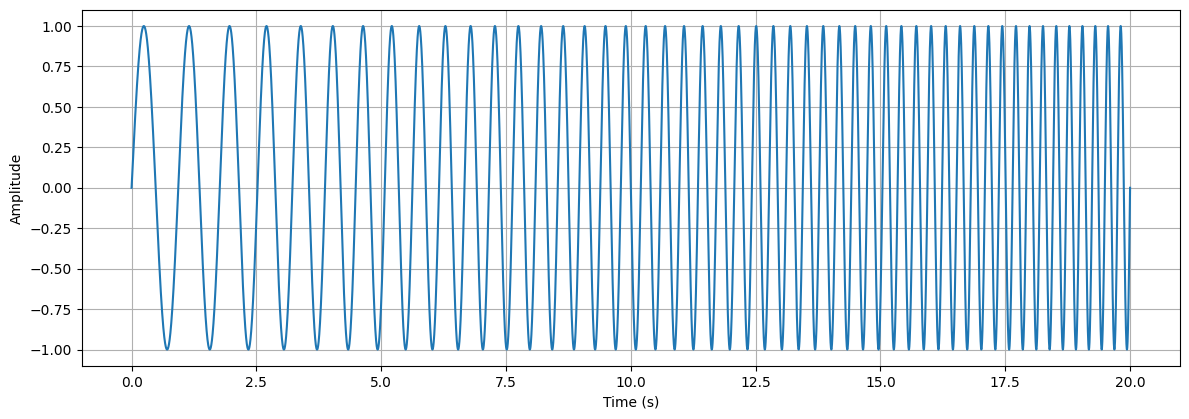

In [6]:
# Parameters
f0 = 1.0  # Initial frequency
b = 0.075  # sweep rate in Hz/s
duration = 20.0  # sweep duration
A = 1.0  # Amplitude constant

# Time array
sample_rate = 1000  # Samples per second (Hz)
t = np.linspace(0, duration, int(duration * sample_rate))  # Time array from 0 to 20 seconds

# phasse
phase = 2 * np.pi * (f0 * t + b * t**2)

# sweep signal
psi = A * np.sin(phase)

# instant frequency
f_t = f0 + 2 * b * t

# plots
plt.figure(figsize=(12, 8))

# sweep signal
plt.subplot(2, 1, 1)
plt.plot(t, psi)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

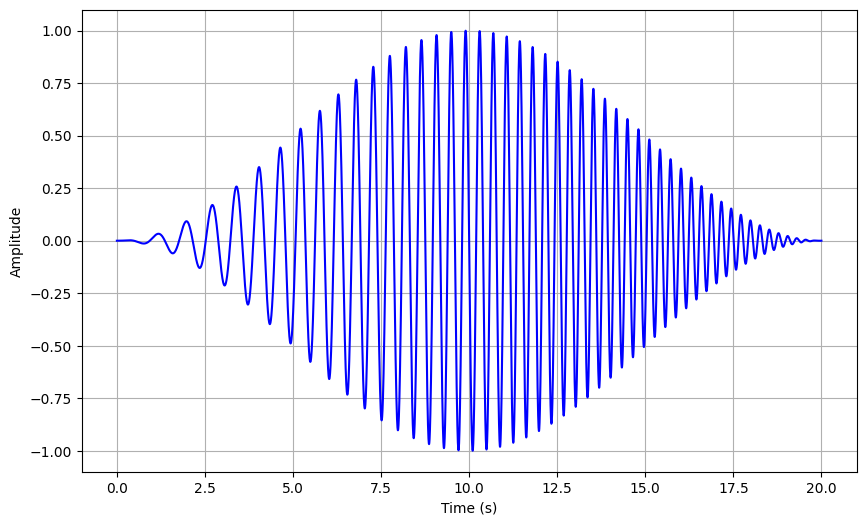

In [7]:
# Parameters from part (a)
f0 = 1.0        # Initial frequency (Hz)
b = 0.075       # Frequency sweep rate (Hz/s)
t_start = 0     # Start time (seconds)
t_end = 20      # End time (seconds)

# Time array with fine resolution (1000 points per second)
sampling_rate = 1000  # Samples per second
t = np.linspace(t_start, t_end, int((t_end - t_start) * sampling_rate))

# Compute the Hanning taper
A_t = np.sin(np.pi * t / 20)**2

# Compute the phase
phase = 2 * np.pi * (f0 * t + b * t**2)

# Compute the vibroseis sweep
psi_t = A_t * np.sin(phase)

#Plot
plt.figure(figsize=(10, 6))
plt.plot(t, psi_t, color='blue')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

## 3C

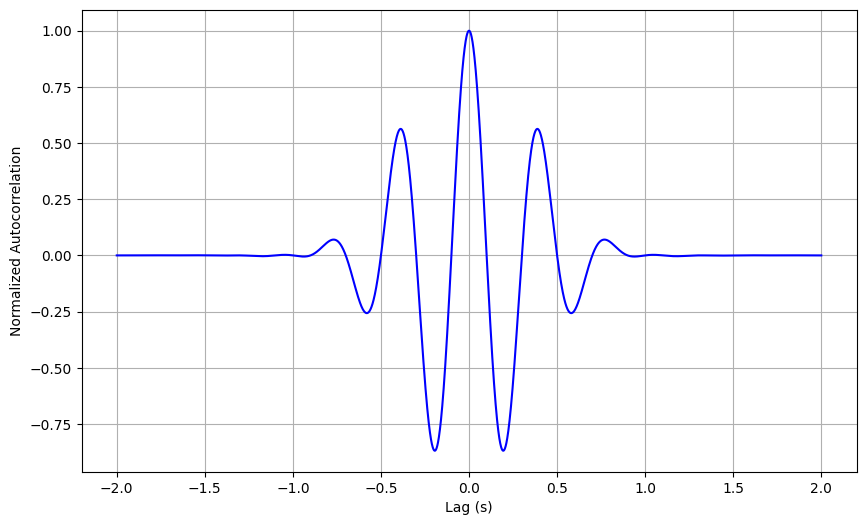

In [8]:
# compute and plot autocorrelation
# Parameters
f0 = 1.0        # Initial frequency
b = 0.075       # sweep rate
t_start = 0     # Start
t_end = 20      # End time
sampling_rate = 1000  # Samples per second

# Time array for psi(t) 0-20
t = np.linspace(t_start, t_end, int((t_end - t_start) * sampling_rate))

# Compute psi(t) w/ Hanning taper
A_t = np.sin(np.pi * t / 20)**2

# Phase phi(t) = 2 * pi * (f0 * t + b * t^2)
phase = 2 * np.pi * (f0 * t + b * t**2)

# Vibroseis sweep function psi(t) = A(t) * sin(phase)
psi_t = A_t * np.sin(phase)

#Compute the autocorrelation w/lags -2 to 2
lag_seconds = 2
lag_samples = int(lag_seconds * sampling_rate)

autocorr = np.correlate(psi_t, psi_t, mode='full')

# The lags corresponding to the autocorrelation
# The center of autocorr is at index len(psi_t) - 1
center = len(psi_t) - 1
lags = np.arange(-center, len(autocorr) - center)  # Lags in samples
lags_seconds = lags / sampling_rate  # Convert lags to seconds

# autocorrelation for lags between -2 and 2 seconds
mask = (lags_seconds >= -lag_seconds) & (lags_seconds <= lag_seconds)
lags_subset = lags_seconds[mask]
autocorr_subset = autocorr[mask]

# Normalize the autocorrelatio
autocorr_subset = autocorr_subset / np.max(autocorr_subset)

# Plot autocorrelation
plt.figure(figsize=(10, 6))
plt.plot(lags_subset, autocorr_subset, color='blue')
plt.xlabel('Lag (s)')
plt.ylabel('Normalized Autocorrelation')
plt.grid(True)
plt.show()

## 3D

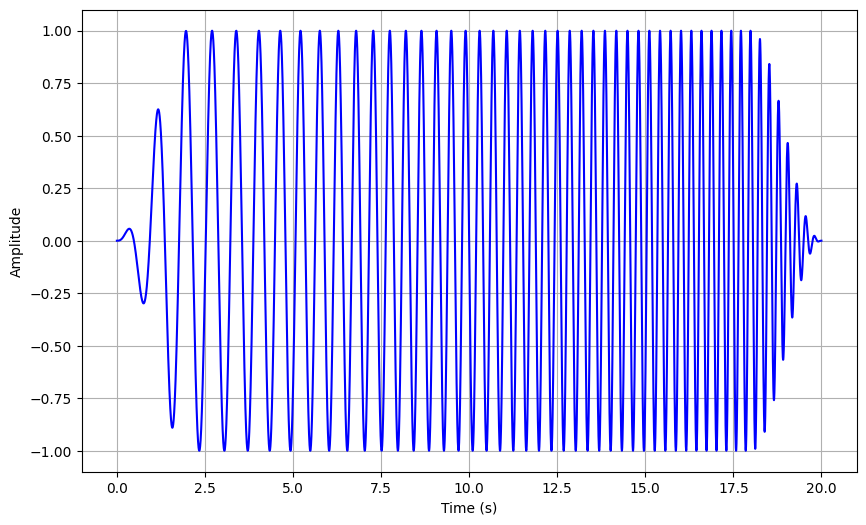

In [9]:
#repeat b and c but assume At is only 2s long taper @each end
# Parameters from previous parts
f0 = 1.0        # Initial frequency
b = 0.075       # sweep rate
t_start = 0     # Start time
t_end = 20      # End time
sampling_rate = 1000

# Time array for psi(t) (0 to 20 seconds)
t = np.linspace(t_start, t_end, int((t_end - t_start) * sampling_rate))

#Compute the new A(t) with 2-second tapers
A_t = np.zeros_like(t)

# Define the three parts of A(t)
for i in range(len(t)):
    if 0 <= t[i] < 2:
        A_t[i] = np.sin(np.pi * t[i] / 4)**2
    elif 2 <= t[i] <= 18:
        A_t[i] = 1
    elif 18 < t[i] <= 20:
        A_t[i] = np.sin(np.pi * (20 - t[i]) / 4)**2

#Compute psi(t) with the new A(t)
phase = 2 * np.pi * (f0 * t + b * t**2)

# Vibroseis sweep function psi(t) = A(t) * sin(phase)
psi_t = A_t * np.sin(phase)

# Plot psi(t) (b)
plt.figure(figsize=(10, 6))
plt.plot(t, psi_t, color='blue')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()


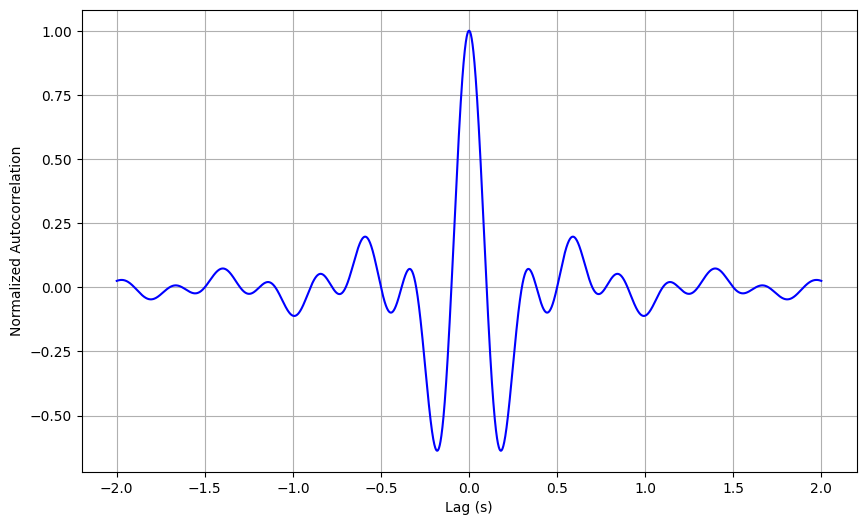

In [10]:
# Compute the autocorrelation of psi(t) (repeating part c)
# We want lags from -2 to 2 seconds
lag_seconds = 2  # Maximum lag in seconds (for -2 to 2 seconds)
lag_samples = int(lag_seconds * sampling_rate)  # Convert to samples

# Use numpy.correlate to compute the autocorrelation
autocorr = np.correlate(psi_t, psi_t, mode='full')

# The lags corresponding to the autocorrelation
center = len(psi_t) - 1
lags = np.arange(-center, len(autocorr) - center)  # Lags in samples
lags_seconds = lags / sampling_rate  # Convert lags to seconds

# Extract the autocorrelation for lags between -2 and 2 seconds
mask = (lags_seconds >= -lag_seconds) & (lags_seconds <= lag_seconds)
lags_subset = lags_seconds[mask]
autocorr_subset = autocorr[mask]

# Normalize the autocorrelation
autocorr_subset = autocorr_subset / np.max(autocorr_subset)

# Plot the autocorrelation
plt.figure(figsize=(10, 6))
plt.plot(lags_subset, autocorr_subset, color='blue')
plt.xlabel('Lag (s)')
plt.ylabel('Normalized Autocorrelation')
plt.grid(True)
plt.show()

# 3E

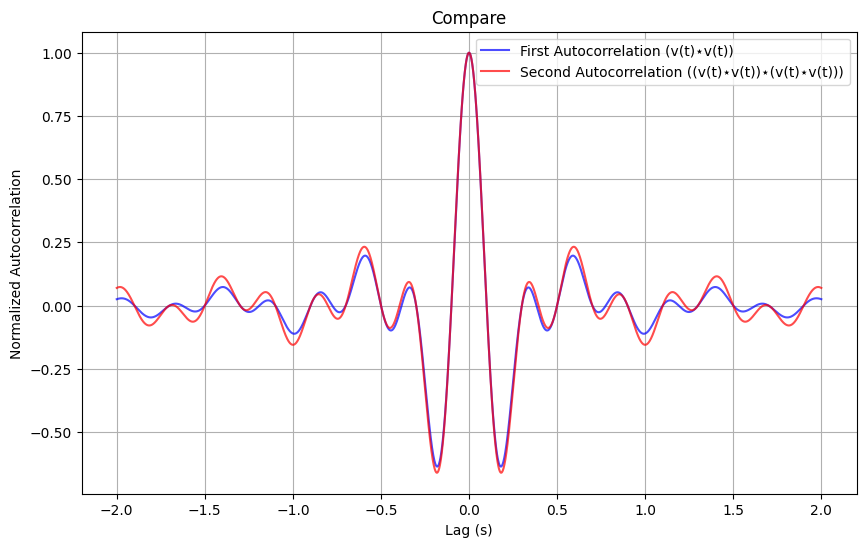

In [11]:
# Parameters from previous parts
f0 = 1.0        # Initial frequency (Hz)
b = 0.075       # Frequency sweep rate (Hz/s)
t_start = 0     # Start time (seconds)
t_end = 20      # End time (seconds)
sampling_rate = 1000  # Samples per second

# Time array for psi(t) (0 to 20 seconds)
t = np.linspace(t_start, t_end, int((t_end - t_start) * sampling_rate))

# Step 1: Compute psi(t) with 2-second Hanning tapers (from part d)
# Compute A(t)
A_t = np.zeros_like(t)
for i in range(len(t)):
    if 0 <= t[i] < 2:
        A_t[i] = np.sin(np.pi * t[i] / 4)**2
    elif 2 <= t[i] <= 18:
        A_t[i] = 1
    elif 18 < t[i] <= 20:
        A_t[i] = np.sin(np.pi * (20 - t[i]) / 4)**2

# Phase phi(t) = 2 * pi * (f0 * t + b * t^2)
phase = 2 * np.pi * (f0 * t + b * t**2)

# Vibroseis sweep function psi(t) = A(t) * sin(phase)
psi_t = A_t * np.sin(phase)

# Step 2: Compute the first autocorrelation (psi(t) ⋆ psi(t))
lag_seconds = 2  # Maximum lag in seconds (for -2 to 2 seconds)
lag_samples = int(lag_seconds * sampling_rate)  # Convert to samples

# First autocorrelation
autocorr1 = np.correlate(psi_t, psi_t, mode='full')

# Lags for the autocorrelation
center = len(psi_t) - 1
lags = np.arange(-center, len(autocorr1) - center)  # Lags in samples
lags_seconds = lags / sampling_rate  # Convert lags to seconds

# Extract for lags between -2 and 2 seconds
mask = (lags_seconds >= -lag_seconds) & (lags_seconds <= lag_seconds)
lags_subset = lags_seconds[mask]
autocorr1_subset = autocorr1[mask]

# Normalize the first autocorrelation
autocorr1_subset = autocorr1_subset / np.max(autocorr1_subset)

# Step 3: Compute the second autocorrelation ((psi(t) ⋆ psi(t)) ⋆ (psi(t) ⋆ psi(t)))
# We need the full autocorrelation for the second step, not just the subset
# autocorr1 is already the full autocorrelation
# Autocorrelate autocorr1 with itself
autocorr2 = np.correlate(autocorr1, autocorr1, mode='full')

# Lags for the second autocorrelation
center2 = len(autocorr1) - 1
lags2 = np.arange(-center2, len(autocorr2) - center2)  # Lags in samples
lags2_seconds = lags2 / sampling_rate  # Convert lags to seconds

# Extract for lags between -2 and 2 seconds
mask2 = (lags2_seconds >= -lag_seconds) & (lags2_seconds <= lag_seconds)
lags2_subset = lags2_seconds[mask2]
autocorr2_subset = autocorr2[mask2]

# Normalize the second autocorrelation
autocorr2_subset = autocorr2_subset / np.max(autocorr2_subset)

# Step 4: Plot both autocorrelations for comparison
plt.figure(figsize=(10, 6))
plt.plot(lags_subset, autocorr1_subset, label='First Autocorrelation (v(t)⋆v(t))', color='blue', alpha=0.7)
plt.plot(lags2_subset, autocorr2_subset, label='Second Autocorrelation ((v(t)⋆v(t))⋆(v(t)⋆v(t)))', color='red', alpha=0.7)
plt.xlabel('Lag (s)')
plt.ylabel('Normalized Autocorrelation')
plt.title('Compare')
plt.legend()
plt.grid(True)
plt.show()